In [1]:
import numpy as np  # 导入数值计算库
import matplotlib.pyplot as plt  # 导入绘图库
import pandas as pd  # 导入数据处理库
import seaborn as sns  # 导入数据可视化库
from sklearn.datasets import load_iris  # 导入数据集加载模块
from sklearn.covariance import EmpiricalCovariance, MinCovDet  # 导入协方差模块
from numpy import linalg as LA  # 导入线性代数模块

In [2]:
iris_sns = sns.load_dataset("iris")  # 使用Seaborn加载iris数据集

SIGMA = iris_sns.iloc[:,:4].cov()  # 计算协方差矩阵
CORR = iris_sns.iloc[:,:4].corr()  # 计算相关系数矩阵
SIGMA = np.array(SIGMA)  # 转换为NumPy数组
CORR = np.array(CORR)  # 转换为NumPy数组

In [3]:
SIGMA_13 = SIGMA[[0, 2], :][:, [0, 2]]  # 提取sepal_length和petal_length的协方差
CORR_13 = CORR[[0, 2], :][:, [0, 2]]  # 提取相关系数
sigma_x = iris_sns['sepal_length'].std()  # 计算sepal_length的标准差
sigma_y = iris_sns['petal_length'].std()  # 计算petal_length的标准差
cov_xy = SIGMA_13[0, 1]  # 提取sepal_length和petal_length的协方差

In [4]:
mu_x = iris_sns['sepal_length'].mean()  # 计算sepal_length的均值
mu_y = iris_sns['petal_length'].mean()  # 计算petal_length的均值

In [5]:
x = np.linspace(3, 9, num=201)  # 生成x坐标数组
y = np.linspace(1, 7, num=201)  # 生成y坐标数组
xx, yy = np.meshgrid(x, y)  # 生成网格，用于绘制等高线

In [6]:
def generate_grid(V, mu_x, mu_y):
    """
    生成旋转后并平移的网格，返回两个网格坐标阵列。
    """
    x1_grid = np.arange(-10, 11, step=1)  # x1方向的网格点
    x2_grid = np.arange(-10, 11, step=1)  # x2方向的网格点
    
    XX1_grid, XX2_grid = np.meshgrid(x1_grid, x2_grid)  # 创建原始网格
    
    X_grid = np.column_stack((XX1_grid.ravel(), XX2_grid.ravel()))  # 将网格点平面展开
    
    Z_grid = X_grid @ V.T  # 旋转网格
    
    ZZ1_grid = Z_grid[:, 0].reshape((len(x1_grid), len(x2_grid)))  # 旋转后的x1坐标
    ZZ2_grid = Z_grid[:, 1].reshape((len(x1_grid), len(x2_grid)))  # 旋转后的x2坐标
    
    ZZ1_grid = ZZ1_grid + mu_x  # 平移x1方向
    ZZ2_grid = ZZ2_grid + mu_y  # 平移x2方向
    
    return ZZ1_grid, ZZ2_grid  # 返回旋转平移后的网格

In [7]:
I = np.array([[1, 0], [0, 1]])  # 单位矩阵，表示无旋转的网格
ZZ1_grid, ZZ2_grid = generate_grid(I, mu_x, mu_y)  # 生成无旋转的平移网格

x_array = np.array(iris_sns["sepal_length"])  # 提取sepal_length数据
y_array = np.array(iris_sns["petal_length"])  # 提取petal_length数据

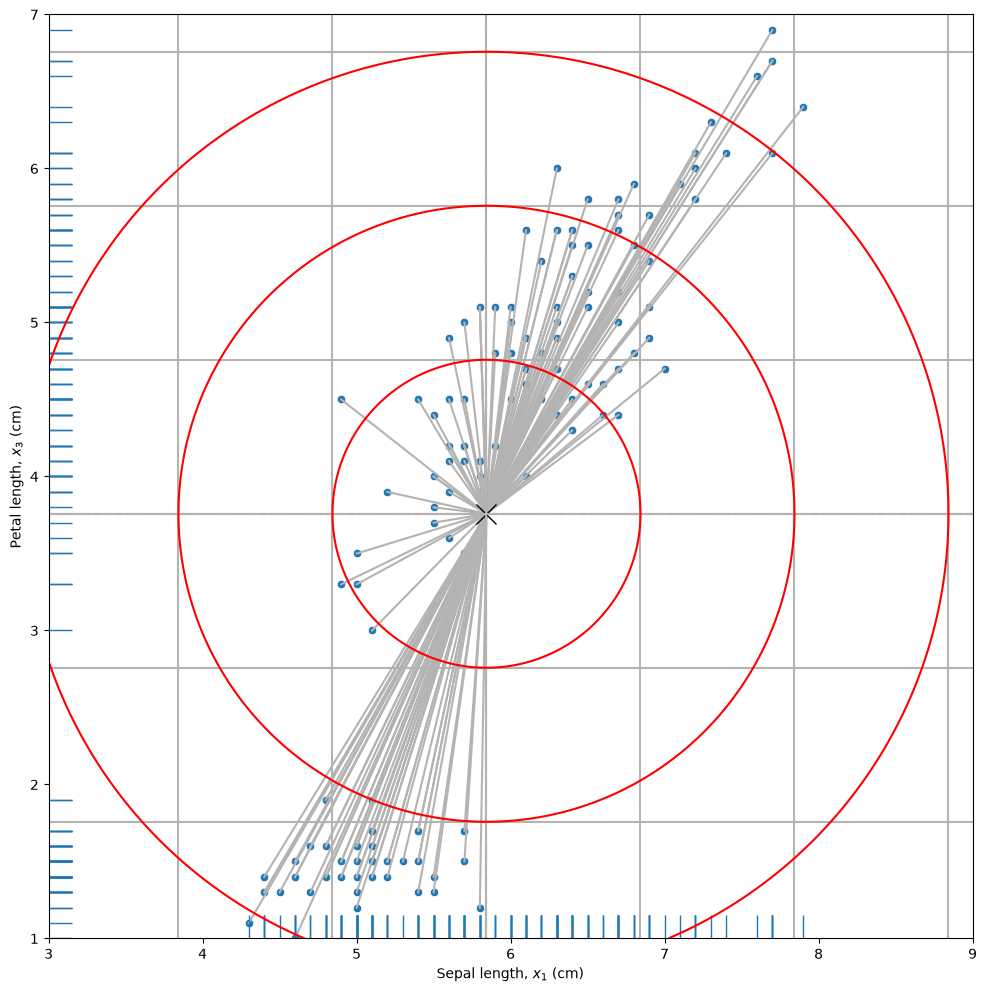

In [8]:
fig, ax = plt.subplots(figsize=(12, 12))  # 创建绘图窗口

plt.plot([x_array, mu_x + x_array * 0], [y_array, mu_y + y_array * 0], color=[0.7, 0.7, 0.7])  # 绘制数据到均值的连线

ax = sns.scatterplot(data=iris_sns, x="sepal_length", y="petal_length")  # 绘制散点图
sns.rugplot(data=iris_sns, x="sepal_length", y="petal_length", ax=ax)  # 绘制边际分布

plt.axvline(x=mu_x, linestyle='--', color='r')  # 绘制x方向均值线
plt.axhline(y=mu_y, linestyle='--', color='r')  # 绘制y方向均值线

plt.plot(mu_x, mu_y, color='k', marker='x', markersize=15)  # 绘制均值点

ax.set_xlabel('Sepal length, $x_1$ (cm)')  # 设置x轴标签
ax.set_ylabel('Petal length, $x_3$ (cm)')  # 设置y轴标签

plt.plot(ZZ1_grid, ZZ2_grid, color=[0.7, 0.7, 0.7])  # 绘制网格
plt.plot(ZZ1_grid.T, ZZ2_grid.T, color=[0.7, 0.7, 0.7])  # 绘制网格的转置

ax.axis('scaled')  # 等比例显示

ax.set_xbound(3, 9)  # 设置x轴范围
ax.set_ybound(1, 7)  # 设置y轴范围

dd = np.sqrt((xx - mu_x) ** 2 + (yy - mu_y) ** 2)  # 计算欧氏距离
ax.contour(xx, yy, dd, levels=[1, 2, 3], colors='r')  # 绘制等距线

In [9]:
D = np.array([[sigma_x, 0], [0, sigma_y]])  # 标准差矩阵
ZZ1_grid, ZZ2_grid = generate_grid(D, mu_x, mu_y)  # 生成标准化网格

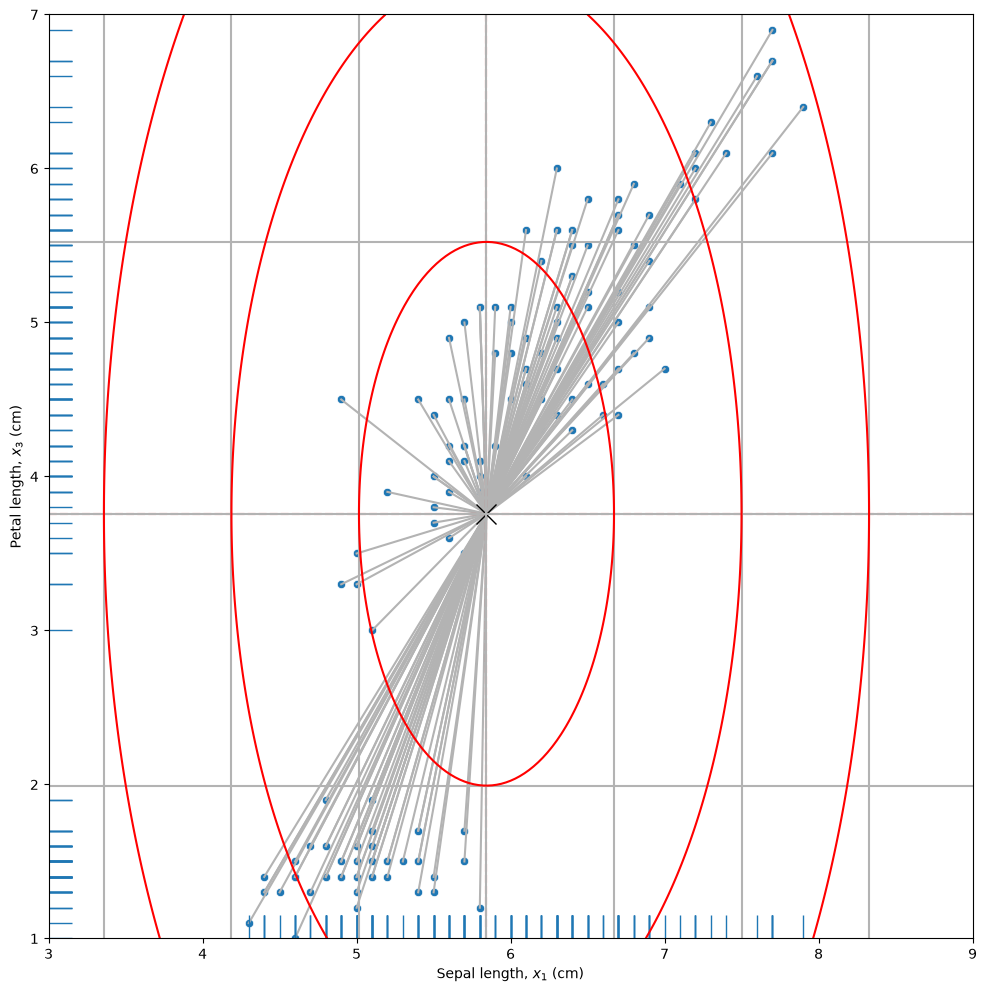

In [10]:
fig, ax = plt.subplots(figsize=(12, 12))  # 创建新绘图窗口

plt.plot([x_array, mu_x + x_array * 0], [y_array, mu_y + y_array * 0], color=[0.7, 0.7, 0.7])  # 数据到均值连线

ax = sns.scatterplot(data=iris_sns, x="sepal_length", y="petal_length")  # 绘制散点图
sns.rugplot(data=iris_sns, x="sepal_length", y="petal_length", ax=ax)  # 边际分布

plt.axvline(x=mu_x, linestyle='--', color='r')  # x均值线
plt.axhline(y=mu_y, linestyle='--', color='r')  # y均值线

plt.plot(mu_x, mu_y, color='k', marker='x', markersize=15)  # 绘制均值点

ax.set_xlabel('Sepal length, $x_1$ (cm)')  # 设置x轴标签
ax.set_ylabel('Petal length, $x_3$ (cm)')  # 设置y轴标签

plt.plot(ZZ1_grid, ZZ2_grid, color=[0.7, 0.7, 0.7])  # 绘制网格
plt.plot(ZZ1_grid.T, ZZ2_grid.T, color=[0.7, 0.7, 0.7])  # 绘制网格的转置

ax.axis('scaled')  # 等比例显示
ax.set_xbound(3, 9)  # 设置x轴范围
ax.set_ybound(1, 7)  # 设置y轴范围

dd = np.sqrt(((xx - mu_x) / sigma_x) ** 2 + ((yy - mu_y) / sigma_y) ** 2)  # 标准化欧氏距离
ax.contour(xx, yy, dd, levels=[1, 2, 3], colors='r')  # 绘制等距线

In [11]:
lambdas, V = LA.eig(SIGMA_13)  # 计算特征值和特征向量

zz_maha = np.c_[xx.ravel(), yy.ravel()]  # 将网格数据平面展开
X = iris_sns.to_numpy()  # 转换iris数据为NumPy数组
X13 = np.array(X[:, [0, 2]], dtype=float)  # 提取特定列
emp_cov_Xc = EmpiricalCovariance().fit(X13)  # 计算经验协方差

mahal_sq_Xc = emp_cov_Xc.mahalanobis(zz_maha)  # 计算马氏距离的平方

mahal_sq_Xc = mahal_sq_Xc.reshape(xx.shape)  # 重塑为网格形状
mahal_d_Xc = np.sqrt(mahal_sq_Xc)  # 计算马氏距离

ZZ1_grid, ZZ2_grid = generate_grid(V @ np.diag(np.sqrt(lambdas)), mu_x, mu_y)  # 生成马氏距离网格

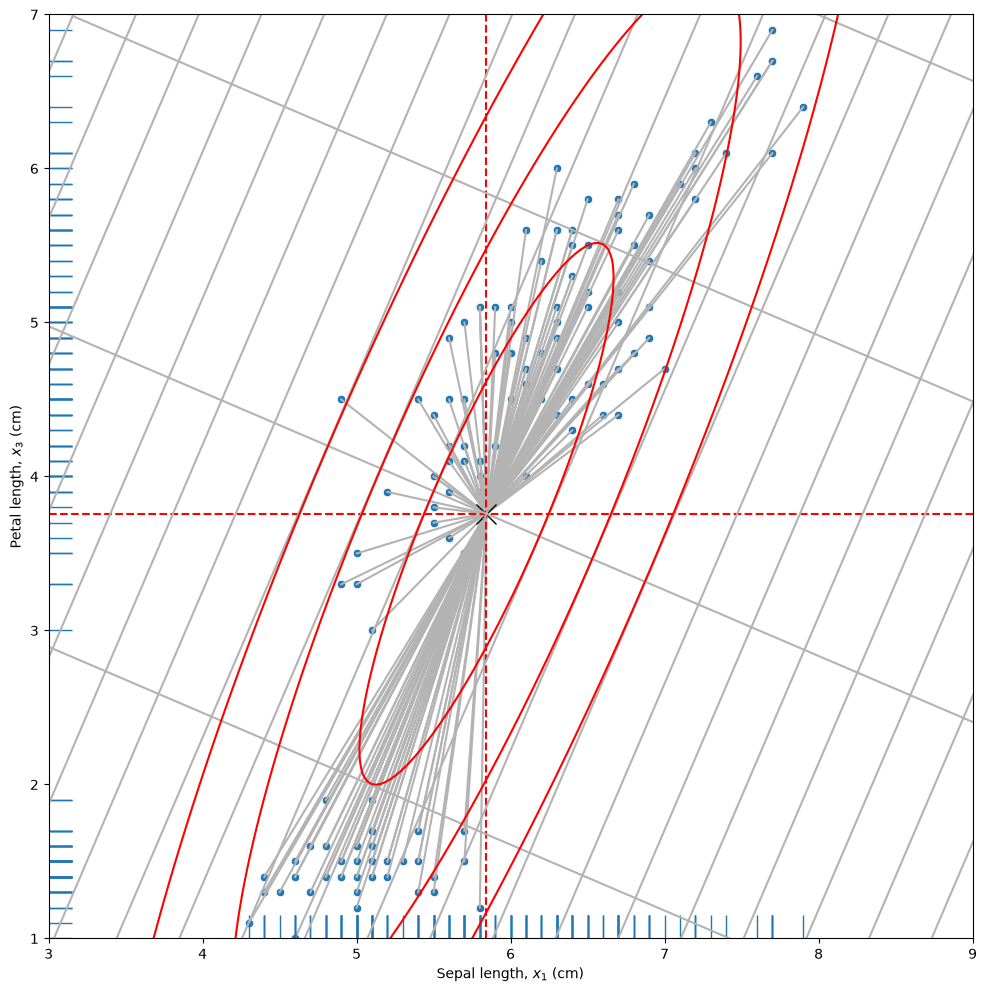

In [12]:
fig, ax = plt.subplots(figsize=(12, 12))  # 创建新绘图窗口

plt.plot([x_array, mu_x + x_array * 0], [y_array, mu_y + y_array * 0], color=[0.7, 0.7, 0.7])  # 数据连线

ax = sns.scatterplot(data=iris_sns, x="sepal_length", y="petal_length")  # 绘制散点图
sns.rugplot(data=iris_sns, x="sepal_length", y="petal_length", ax=ax)  # 边际分布

plt.axvline(x=mu_x, linestyle='--', color='r')  # x均值线
plt.axhline(y=mu_y, linestyle='--', color='r')  # y均值线

plt.plot(mu_x, mu_y, color='k', marker='x', markersize=15)  # 绘制均值点

ax.set_xlabel('Sepal length, $x_1$ (cm)')  # 设置x轴标签
ax.set_ylabel('Petal length, $x_3$ (cm)')  # 设置y轴标签

plt.plot(ZZ1_grid, ZZ2_grid, color=[0.7, 0.7, 0.7])  # 绘制网格
plt.plot(ZZ1_grid.T, ZZ2_grid.T, color=[0.7, 0.7, 0.7])  # 绘制网格的转置

ax.axis('scaled')  # 等比例显示
ax.set_xbound(3, 9)  # 设置x轴范围
ax.set_ybound(1, 7)  # 设置y轴范围

ax.contour(xx, yy, mahal_d_Xc, levels=[1, 2, 3], colors='r')  # 绘制马氏距离等距线

In [13]:
import numpy as np  # 导入数值计算库
import matplotlib.pyplot as plt  # 导入绘图库
import pandas as pd  # 导入数据处理库
from statsmodels.distributions.empirical_distribution import ECDF  # 导入经验分布函数
from scipy.stats import norm  # 导入正态分布模块
import scipy  # 导入科学计算库
import seaborn as sns  # 导入数据可视化库

In [14]:
iris_sns = sns.load_dataset("iris")  # 使用Seaborn加载iris数据集

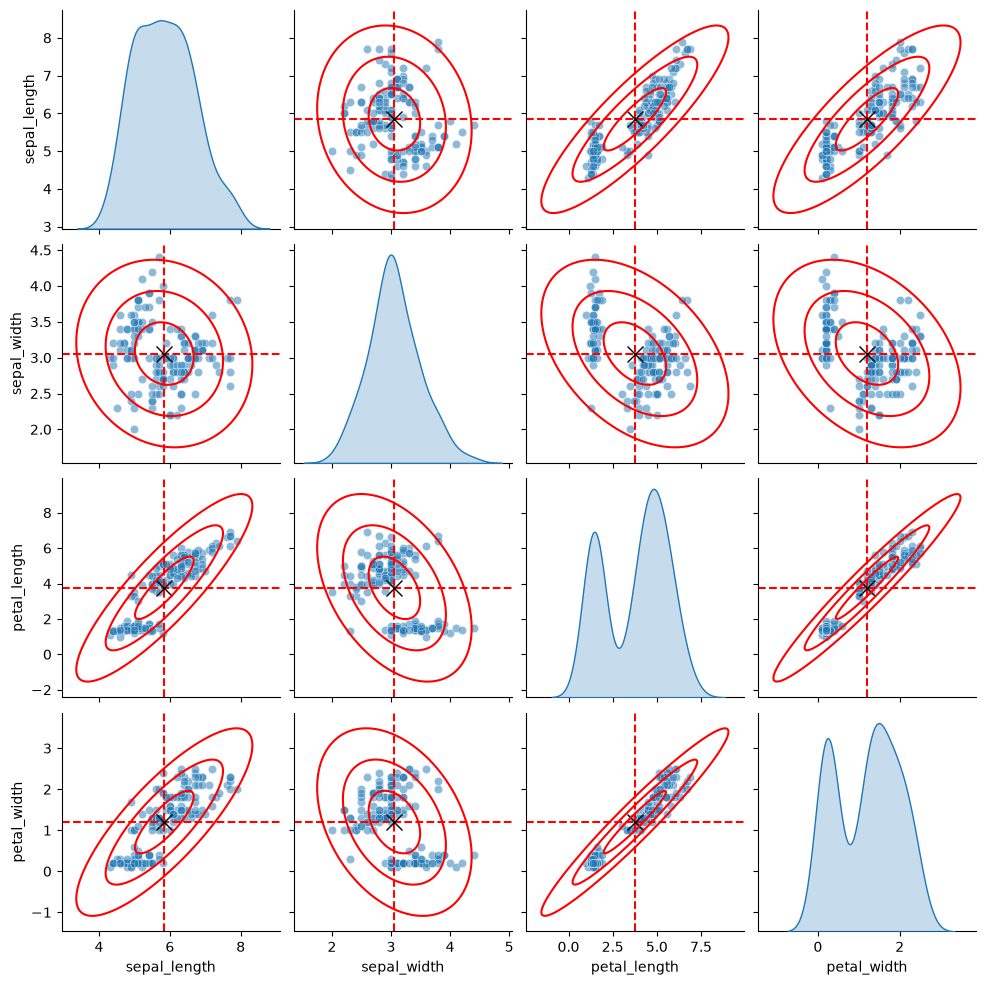

In [15]:
SIGMA = iris_sns.iloc[:,:4].cov()  # 计算协方差矩阵
SIGMA = np.array(SIGMA)  # 转换为NumPy数组格式

MU = iris_sns.iloc[:,:4].mean()  # 计算各变量的均值
MU = np.array(MU)  # 转换为NumPy数组格式

g = sns.pairplot(iris_sns, diag_kind='kde', kind='scatter', plot_kws={'alpha': 0.5})  # 创建成对关系图

for i in [0, 1, 2, 3]:  # 遍历变量组合
    for j in [0, 1, 2, 3]:
        if i == j:  # 跳过对角线
            pass
        else:
            ax = g.axes[i][j]  # 获取当前子图
            mu_x = MU[j]  # 当前变量x的均值
            mu_y = MU[i]  # 当前变量y的均值
            
            ax.axvline(x=mu_x, color='r', linestyle='--')  # 绘制x的均值线
            ax.axhline(y=mu_y, color='r', linestyle='--')  # 绘制y的均值线
            ax.plot(mu_x, mu_y, color='k', marker='x', markersize=12)  # 标记均值点
            
            sigma_X = np.sqrt(SIGMA[j][j])  # 计算x的标准差
            sigma_Y = np.sqrt(SIGMA[i][i])  # 计算y的标准差
            
            x = np.linspace(mu_x - 3.5 * sigma_X, mu_x + 3.5 * sigma_X, num=201)  # x的取值范围
            y = np.linspace(mu_y - 3.5 * sigma_Y, mu_y + 3.5 * sigma_Y, num=201)  # y的取值范围
            
            xx, yy = np.meshgrid(x, y)  # 创建网格
            cov_X_Y = SIGMA[i][j]  # 获取x和y的协方差
            rho = cov_X_Y / sigma_X / sigma_Y  # 计算相关系数
            
            ellipse = (((xx - mu_x) / sigma_X) ** 2 - 
                       2 * rho * ((xx - mu_x) / sigma_X) * ((yy - mu_y) / sigma_Y) + 
                       ((yy - mu_y) / sigma_Y) ** 2) / (1 - rho ** 2)  # 计算椭圆方程
            ellipse = np.sqrt(ellipse)
            
            ax.contour(xx, yy, ellipse, levels=[1, 2, 3], colors='r')  # 绘制等距椭圆

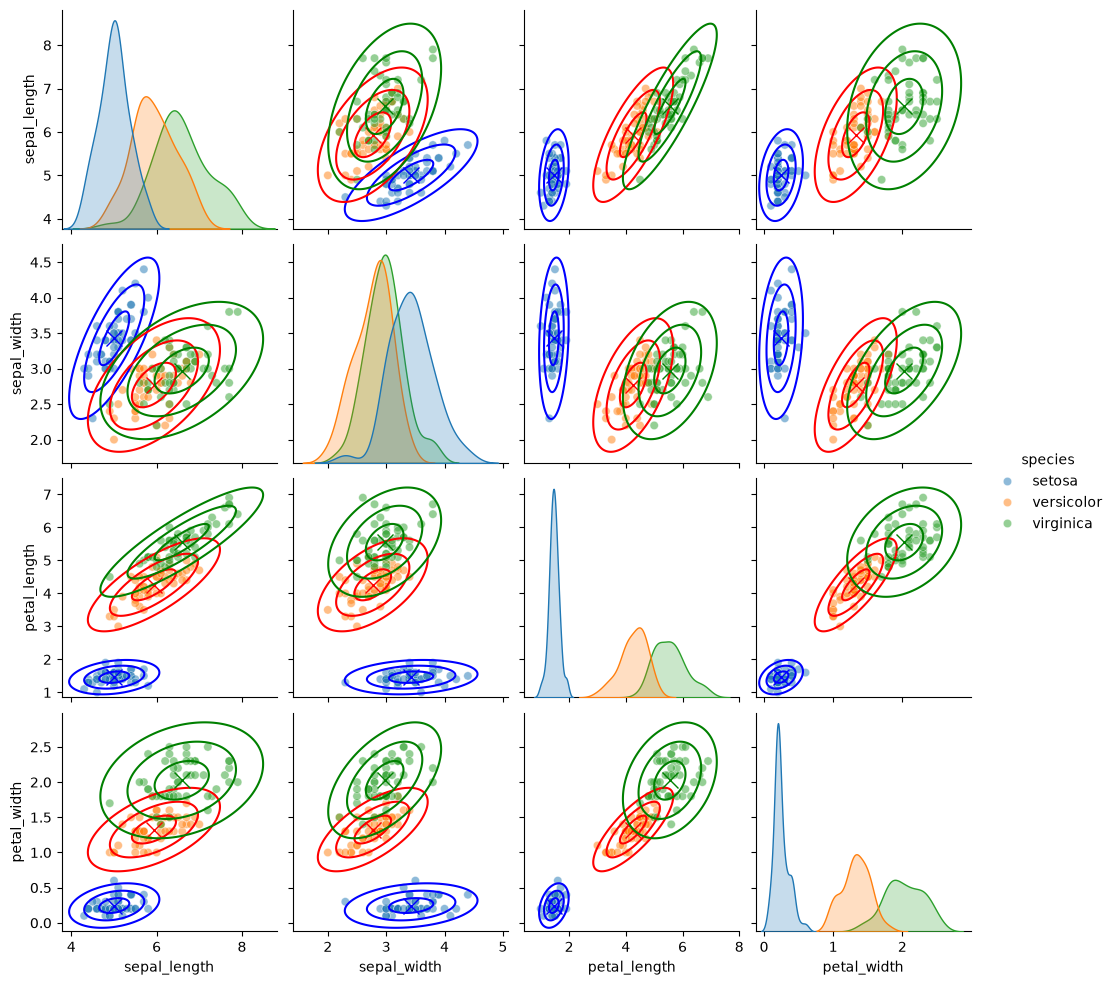

In [16]:
dimensions = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']  # 定义变量名称列表

g = sns.pairplot(iris_sns, hue="species", kind='scatter', plot_kws={'alpha': 0.5})  # 创建带分类标签的成对关系图
colors = ['b', 'r', 'g']  # 为不同类别定义颜色

for i, i_dim in enumerate(dimensions):  # 遍历变量组合
    for j, j_dim in enumerate(dimensions):
        if i == j:  # 跳过对角线
            pass
        else:
            ax = g.axes[i][j]  # 获取当前子图
            
            for k, label in enumerate(iris_sns['species'].unique()):  # 遍历每个类别
                
                data = iris_sns.loc[iris_sns['species'] == label, [i_dim, j_dim]]  # 获取当前类别的数据
                
                mu_i_j = data.mean()  # 计算均值
                mu_x = mu_i_j.iloc[1]  # x的均值，使用 iloc 明确表示位置索引
                mu_y = mu_i_j.iloc[0]  # y的均值，使用 iloc 明确表示位置索引
                
                SIGMA_i_j = data.cov()  # 计算协方差矩阵
                CORR_i_j  = data.corr()  # 计算相关系数矩阵
                
                SIGMA_i_j = np.array(SIGMA_i_j)  # 转换为NumPy数组
                CORR_i_j  = np.array(CORR_i_j)  # 转换为NumPy数组
            
                ax.plot(mu_x, mu_y, color=colors[k], marker='x', markersize=12)  # 标记均值点
                
                sigma_X = np.sqrt(SIGMA_i_j[1][1])  # x的标准差
                sigma_Y = np.sqrt(SIGMA_i_j[0][0])  # y的标准差
                
                x = np.linspace(mu_x - 3.5 * sigma_X, mu_x + 3.5 * sigma_X, num=201)  # x的取值范围
                y = np.linspace(mu_y - 3.5 * sigma_Y, mu_y + 3.5 * sigma_Y, num=201)  # y的取值范围
                
                xx, yy = np.meshgrid(x, y)  # 创建网格
                rho = CORR_i_j[0][1]  # 获取相关系数
                
                ellipse = (((xx - mu_x) / sigma_X) ** 2 - 
                           2 * rho * ((xx - mu_x) / sigma_X) * ((yy - mu_y) / sigma_Y) + 
                           ((yy - mu_y) / sigma_Y) ** 2) / (1 - rho ** 2)  # 计算椭圆方程
                ellipse = np.sqrt(ellipse)
                
                # print(str(i_dim) + '_' + str(j_dim) + '_' + str(rho))  # 输出变量及其相关系数信息
                
                ax.contour(xx, yy, ellipse, levels=[1, 2, 3], colors=colors[k])  # 绘制不同类别的等距椭圆


In [17]:
import numpy as np  # 导入数值计算库
from sklearn.covariance import EmpiricalCovariance  # 导入协方差计算模块

In [18]:
SIGMA = np.array([[5, 3], [3, 5]]) / 8  # 定义协方差矩阵
mu = np.array([0, 0])  # 定义均值向量

In [19]:
R1, R2 = np.random.multivariate_normal(mu, SIGMA, 1000).T  # 生成1000个数据点并转置

In [20]:
x1 = np.linspace(-3, 3, 100)  # x1方向上的范围
x2 = x1 

[X1, X2] = np.meshgrid(x1, x2)  # 创建x1和x2的网格

X = np.array([X1.flatten(), X2.flatten()]).T  # 将网格展平，并组合成坐标点数组

In [21]:
emp_cov_Xc = EmpiricalCovariance().fit(np.vstack((R1, R2)).T)  # 计算经验协方差

mahal_sq_Xc = emp_cov_Xc.mahalanobis(X)  # 计算马氏距离的平方
mahal_sq_Xc = mahal_sq_Xc.reshape(X1.shape)  # 将结果重塑为网格形状
mahal_d_Xc = np.sqrt(mahal_sq_Xc)  # 计算马氏距离

(np.float64(-3.0), np.float64(3.0), np.float64(-3.0), np.float64(3.0))

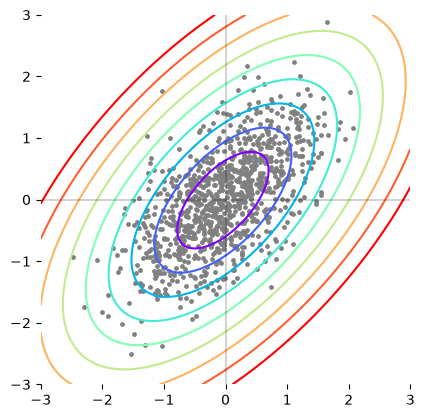

In [22]:
import matplotlib.pyplot as plt  # 导入绘图库

levels = np.linspace(1, 5, 9)  # 设置等高线的水平

fig, ax = plt.subplots()  # 创建绘图窗口

ax.contour(X1, X2, mahal_d_Xc, levels=levels, cmap='rainbow')  # 绘制马氏距离等高线
plt.scatter(R1, R2, s=6, color=[0.5, 0.5, 0.5])  # 绘制随机数据散点图

ax.axhline(y=0, color='k', linewidth=0.25)  # 绘制y轴参考线
ax.axvline(x=0, color='k', linewidth=0.25)  # 绘制x轴参考线
ax.set_xlim(-3, 3)  # 设置x轴显示范围
ax.set_ylim(-3, 3)  # 设置y轴显示范围
ax.spines['top'].set_visible(False)  # 隐藏上边框
ax.spines['right'].set_visible(False)  # 隐藏右边框
ax.spines['bottom'].set_visible(False)  # 隐藏下边框
ax.spines['left'].set_visible(False)  # 隐藏左边框
plt.axis('scaled')  # 设置坐标比例相同

(np.float64(-3.0), np.float64(3.0), np.float64(-3.0), np.float64(3.0))

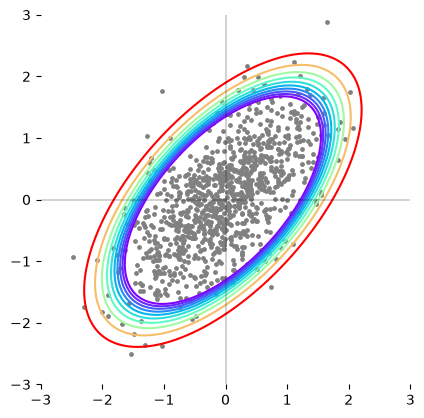

In [23]:
intervals = np.linspace(0.9, 0.99, 10)  # 定义置信区间

from scipy.stats.distributions import chi2  # 导入卡方分布模块

dist_chi2_sqrt = np.sqrt(chi2.ppf(intervals, df=2))  # 计算对应卡方分布的分位数

fig, ax = plt.subplots()  # 创建新的绘图窗口

ax.contour(X1, X2, mahal_d_Xc, levels=dist_chi2_sqrt, cmap='rainbow')  # 绘制马氏距离的卡方分布等高线
plt.scatter(R1, R2, s=6, color=[0.5, 0.5, 0.5])  # 绘制随机数据散点图

ax.axhline(y=0, color='k', linewidth=0.25)  # 绘制y轴参考线
ax.axvline(x=0, color='k', linewidth=0.25)  # 绘制x轴参考线
ax.set_xlim(-3, 3)  # 设置x轴显示范围
ax.set_ylim(-3, 3)  # 设置y轴显示范围
ax.spines['top'].set_visible(False)  # 隐藏上边框
ax.spines['right'].set_visible(False)  # 隐藏右边框
ax.spines['bottom'].set_visible(False)  # 隐藏下边框
ax.spines['left'].set_visible(False)  # 隐藏左边框
plt.axis('scaled')  # 设置坐标比例相同

In [24]:
import numpy as np  # 导入数值计算库
import matplotlib.pyplot as plt  # 导入绘图库
from scipy.stats.distributions import chi2  # 导入卡方分布模块

In [25]:
intervals = np.linspace(0.9, 0.99, 11)  # 设置置信区间
dist_chi2_sqrt = np.sqrt(chi2.ppf(intervals, df=2))  # 根据卡方分布计算分位数对应的马氏距离

In [26]:
num_sigma = np.linspace(1, 3, 3)  # 设置标准差的倍数范围
prob = chi2.cdf(num_sigma ** 2, df=2)  # 计算不同倍数标准差的累积分布概率

Text(0, 0.5, '$\\alpha$')

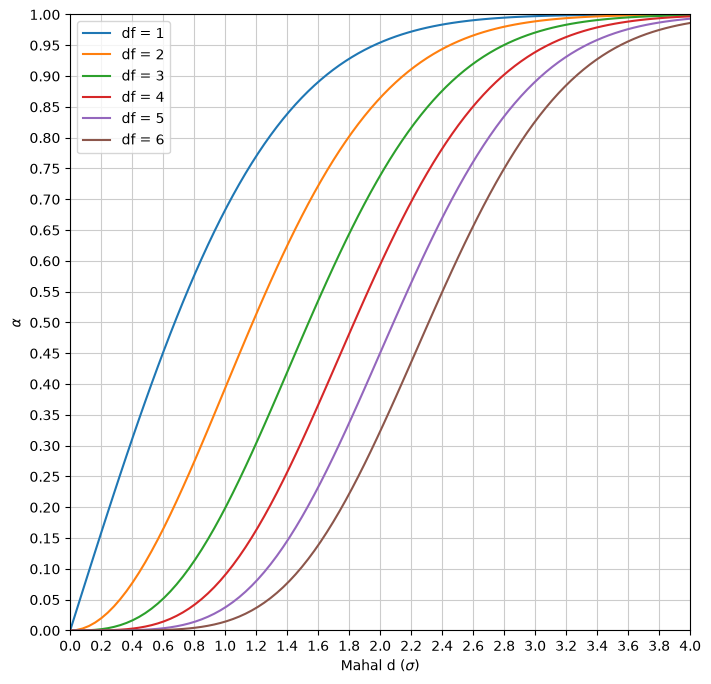

In [27]:
x = np.linspace(0, 4, 100)  # 设置x轴的马氏距离范围

fig, ax = plt.subplots(figsize=(8, 8))  # 创建绘图窗口

for df in [1, 2, 3, 4, 5, 6]:  # 遍历不同的自由度
    prob_x_df_D = chi2.cdf(x ** 2, df=df)  # 计算不同自由度的累积分布概率
    plt.plot(x, prob_x_df_D, label='df = ' + str(df))  # 绘制不同自由度下的曲线

plt.grid(color=(0.8, 0.8, 0.8))  # 设置网格颜色
plt.legend()  # 显示图例
plt.yticks(np.linspace(0, 1, 21))  # 设置y轴刻度
plt.xticks(np.linspace(0, 4, 21))  # 设置x轴刻度

plt.xlim(0, 4)  # 设置x轴显示范围
plt.ylim(0, 1)  # 设置y轴显示范围
plt.xlabel(r'Mahal d ($\sigma$)')  # 设置x轴标签
plt.ylabel(r'$\alpha$')  # 设置y轴标签